# Antenna path on the half-wave grid

This notebook walks through the antenna branch of `fast_interferometer`, then the `N_uv` branch on the same sky. Passing `ant_locs` (and no `N_uv`) takes the half-wave path. Passing `N_uv` sizes the pad from the supplied cell spacing instead.

One grid is used for the baselines and for the sky. Its cells are half a wavelength (`du = dv = 0.5`), `u = 0` is a cell centre, and the axis stops at the Nyquist limit of the sky pixels. The sky is copied into a larger image whose Fourier transform lands on that grid. Nothing is interpolated.

## What `get_dirty_map` calls

```text
get_dirty_map
  get_uvmap_halfwave
    get_bls                          baselines in metres, then u, v in wavelengths
    _set_hybrid_grid(0.5, 0.5)       du = dv = 0.5, extent = sky Nyquist
    _array_layout_from_baselines     '2d', 'ew_only', or 'ns_only'
    _grid_baselines_on_halfwave      nearest cell; uv_map is the count map
  _dirty_map_halfwave
    _pad_sky                         copy the sky in by pixel index
    FFT                              padded sky -> half-wave visibilities
    multiply by uv_map
    _ifft_uv_to_sky                  inverse FFT, then _crop_to_sky
    divide by sum(weight) * du * dv * dl * dm
```

`get_psf` calls `get_uvmap_halfwave` and then `_ifft_uv_to_sky` on the count map alone.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import units
from matplotlib.patches import Rectangle

from limstat.fast_interferometer import fast_interferometer

%load_ext autoreload
%autoreload 2

## Sky and instrument

The field of view and the pixel count fix the grid. Antenna positions are not needed yet. `dl = sin(theta) / npix` is the sky pixel size, and the padded image has `n = round(2 / dl)` pixels so that an FFT with that spacing has `du = 0.5`.

In [2]:
freq = 150 * units.MHz
wavelength = (3e8 * units.m / units.s / freq.to(units.Hz)).to(units.m)
fov = 10 * units.deg
npix =200

inst = fast_interferometer(
    theta_x=fov,
    theta_y=fov,
    x_npix=npix,
    y_npix=npix,
)

yy, xx = np.mgrid[0:npix, 0:npix]
cy, cx = npix // 2, npix // 2
sigma = 4.0
sky = np.exp(-((xx - cx + 10) ** 2 + (yy - cy - 6) ** 2) / (2 * sigma ** 2))

dl, dm = inst._set_hybrid_grid(0.5, 0.5)


print(f'wavelength {wavelength:.3f}')
print(f'dl = dm = {dl:.6f}')
print(f'padded image {inst.n_pad_y} x {inst.n_pad_x}, pixel size {2 / inst.n_pad_x:.6f}')
print(f'du = dv = {inst.du}')
print(f'sky Nyquist |u| <= {1 / (2 * dl):.2f} wavelengths')

UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
wavelength 2.000 m
dl = dm = 0.000868
padded image 2304 x 2304, pixel size 0.000868
du = dv = 0.5
sky Nyquist |u| <= 575.88 wavelengths


## Original sky, padded sky, Fourier transform

`_pad_sky` writes the sky into the middle of an image that is 2 wide in direction cosine. The box on the middle panel is the original sky. The Fourier transform is the same one `_dirty_map_halfwave` takes: `fftshift(fft2(ifftshift(padded))) * dl * dm`. Its pixels are the half-wave cells.

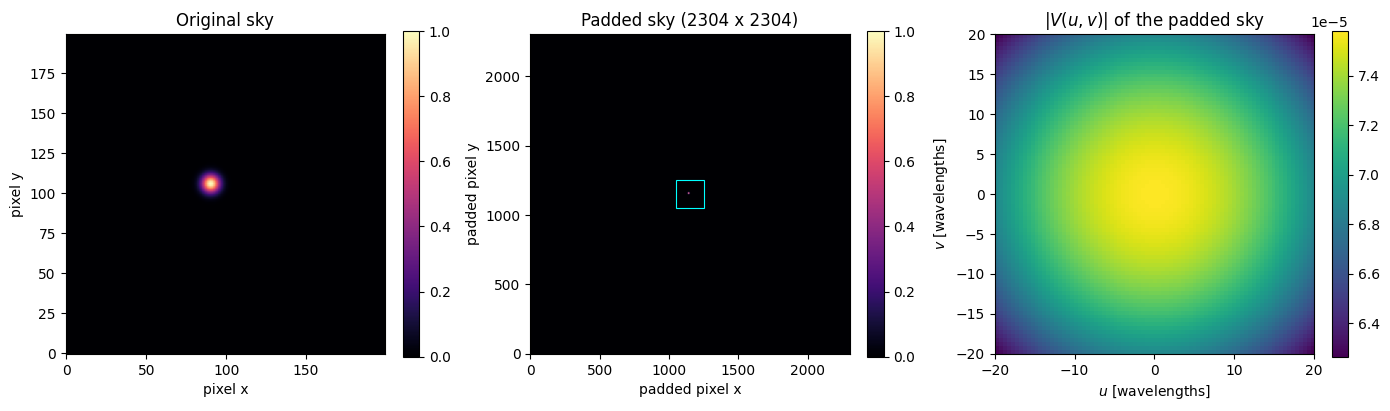

In [3]:
padded = inst._pad_sky(sky)
y0, x0 = inst._sky_origin()


V = (
    np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(padded, axes=(0, 1))))
    * (dl * dm)
)

u_cent = 0.5 * (inst.u_grid[:-1] + inst.u_grid[1:])
v_cent = 0.5 * (inst.v_grid[:-1] + inst.v_grid[1:])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

im0 = axes[0].imshow(sky, origin='lower', cmap='magma')
axes[0].set_title('Original sky')
axes[0].set_xlabel('pixel x')
axes[0].set_ylabel('pixel y')
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(padded, origin='lower', cmap='magma')
axes[1].add_patch(Rectangle(
    (x0 - 0.5, y0 - 0.5), npix, npix, fill=False, edgecolor='cyan', linewidth=0.8,
))
axes[1].set_title(f'Padded sky ({padded.shape[0]} x {padded.shape[1]})')
axes[1].set_xlabel('padded pixel x')
axes[1].set_ylabel('padded pixel y')
fig.colorbar(im1, ax=axes[1], fraction=0.046)

half = 40
iu = np.argmin(np.abs(u_cent))
iv = np.argmin(np.abs(v_cent))
sl = np.s_[iv - half:iv + half + 1, iu - half:iu + half + 1]
im2 = axes[2].imshow(
    np.abs(V[sl]),
    origin='lower',
    cmap='viridis',
    extent=[u_cent[iu - half], u_cent[iu + half], v_cent[iv - half], v_cent[iv + half]],
)
axes[2].set_title(r'$|V(u, v)|$ of the padded sky')
axes[2].set_xlabel(r'$u$ [wavelengths]')
axes[2].set_ylabel(r'$v$ [wavelengths]')
axes[2].set_aspect('equal')
fig.colorbar(im2, ax=axes[2], fraction=0.046)

fig.tight_layout()

## Random array, counts on the hybrid grid, PSF

`get_uvmap_halfwave` calls `get_bls`, builds this same grid, and bins each baseline into the nearest cell with `_grid_baselines_on_halfwave`. The returned map is the natural weight, `count_map`. A baseline is kept only when it and its conjugate both land inside the sky Nyquist limit.

The count map is the full hybrid grid, so the baselines occupy the middle. The right-hand zoom is that middle. `get_psf` inverse-transforms the count map and crops back to the original sky pixels.

1560 total baseline vectors, 1560 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
layout 2d
u = 0 is cell index 1152, centre 0.000
baselines kept (sum of counts) 1560
longest kept |u| 39.0 wavelengths
1560 total baseline vectors, 1560 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)


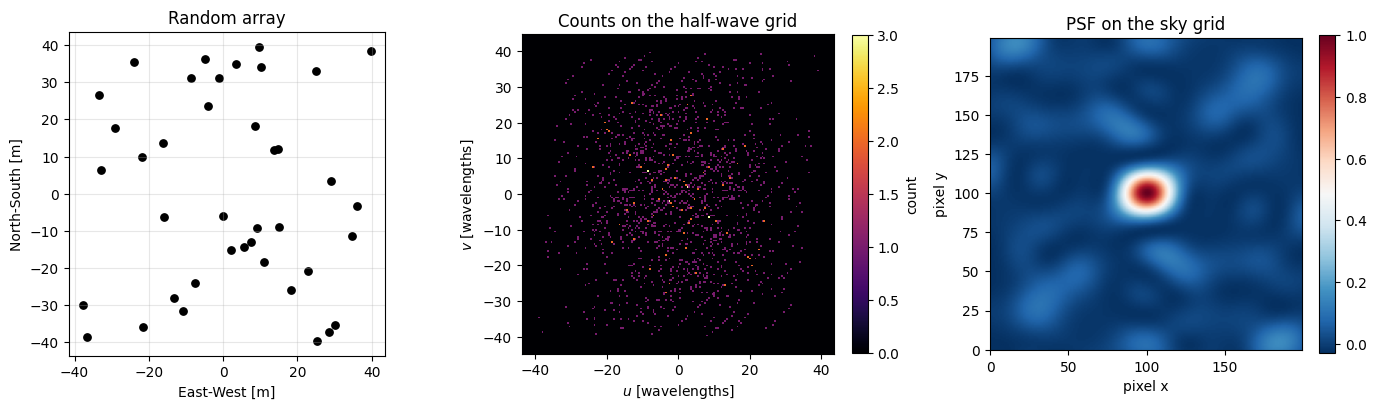

In [4]:
rng = np.random.default_rng(0)
aperture_m = 80.0
ant_locs = rng.uniform(-aperture_m / 2, aperture_m / 2, size=(40, 2)) * units.m

uv_map = inst.get_uvmap_halfwave(freq, ant_locs=ant_locs)
u_cent = 0.5 * (inst.u_grid[:-1] + inst.u_grid[1:])
v_cent = 0.5 * (inst.v_grid[:-1] + inst.v_grid[1:])

N_uv_random = (inst.u_grid, inst.v_grid, uv_map)
print(f'layout {inst.array_layout}')
print(f'u = 0 is cell index {inst.n_pad_x // 2}, centre {u_cent[inst.n_pad_x // 2]:.3f}')
print(f'baselines kept (sum of counts) {uv_map.sum():.0f}')
print(f'longest kept |u| {np.abs(u_cent[np.any(uv_map > 0, axis=0)]).max():.1f} wavelengths')

psf = inst.get_psf(freq, ant_locs=ant_locs, peak_normalize=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

ants_m = ant_locs.to(units.m).value
axes[0].scatter(ants_m[:, 0], ants_m[:, 1], s=28, c='k')
axes[0].set_aspect('equal')
axes[0].set_xlabel('East-West [m]')
axes[0].set_ylabel('North-South [m]')
axes[0].set_title('Random array')
axes[0].grid(True, alpha=0.3)

u_lim = np.abs(inst.u_coords).max() + 5
v_lim = np.abs(inst.v_coords).max() + 5
im1 = axes[1].imshow(
    uv_map,
    origin='lower',
    cmap='inferno',
    interpolation='none',
    extent=[inst.u_grid[0], inst.u_grid[-1], inst.v_grid[0], inst.v_grid[-1]],
)
axes[1].set_xlim(-u_lim, u_lim)
axes[1].set_ylim(-v_lim, v_lim)
axes[1].set_aspect('equal')
axes[1].set_xlabel(r'$u$ [wavelengths]')
axes[1].set_ylabel(r'$v$ [wavelengths]')
axes[1].set_title('Counts on the half-wave grid')
fig.colorbar(im1, ax=axes[1], fraction=0.046, label='count')

im2 = axes[2].imshow(psf, origin='lower', cmap='RdBu_r')
axes[2].set_title('PSF on the sky grid')
axes[2].set_xlabel('pixel x')
axes[2].set_ylabel('pixel y')
fig.colorbar(im2, ax=axes[2], fraction=0.046)

fig.tight_layout()

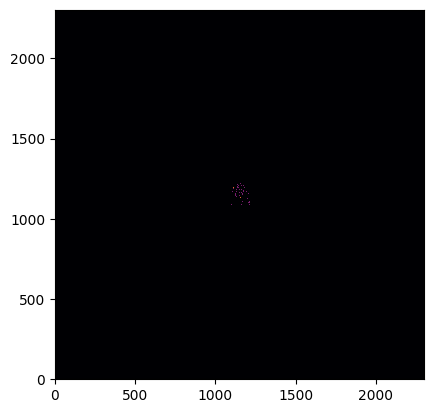

In [5]:
plt.imshow(uv_map, origin='lower', cmap='inferno', interpolation='none')

## Dirty map

`get_dirty_map` runs the chain above. It multiplies the padded-sky transform by the count map, inverse-transforms, crops to the original pixels, and divides by `count_map.sum() * du * dv`, which is the peak of the un-normalised PSF.

1560 total baseline vectors, 1560 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
dirty map (200, 200), weight normalisation 0.000294


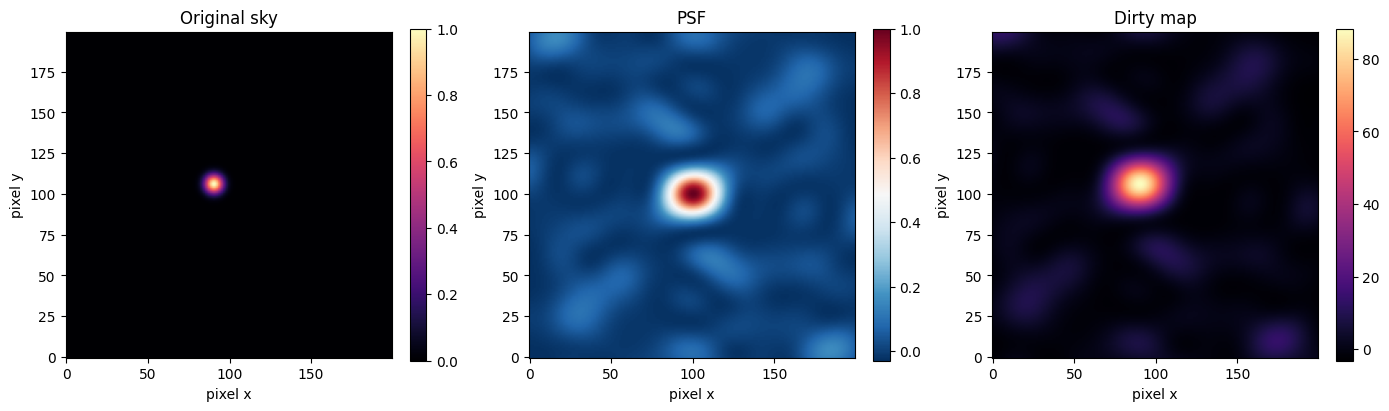

In [6]:
dirty = inst.get_dirty_map(sky, freq, ant_locs=ant_locs, noise=False)
peak = float(np.sum(inst.count_map) * inst.du * inst.dv * dl * dm)
print(f'dirty map {dirty.shape}, weight normalisation {peak:.4g}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

im0 = axes[0].imshow(sky, origin='lower', cmap='magma')
axes[0].set_title('Original sky')
axes[0].set_xlabel('pixel x')
axes[0].set_ylabel('pixel y')
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(psf, origin='lower', cmap='RdBu_r')
axes[1].set_title('PSF')
axes[1].set_xlabel('pixel x')
axes[1].set_ylabel('pixel y')
fig.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(dirty, origin='lower', cmap='magma')
axes[2].set_title('Dirty map')
axes[2].set_xlabel('pixel x')
axes[2].set_ylabel('pixel y')
fig.colorbar(im2, ax=axes[2], fraction=0.046)

fig.tight_layout()

## Check: `N_uv` on the same sky

`N_uv = (u_grid, v_grid, count_map)` does not use antennas. `get_uvmap_halfwave(..., N_uv=N_uv)` reads `du` and `dv` from the median edge spacing, sizes the pad with `n_pad = round(1 / (du * dl))`, and nearest-cells the input counts onto that plane. Cells outside the sky Nyquist limit are dropped.

The PSF is the inverse transform of those padded counts, cropped back to the original sky. `get_dirty_map` multiplies, inverse-transforms, and crops the same way.

In [7]:
N_uv_sky = np.zeros_like(sky)+ 1
u_sky, v_sky, l_sky, m_sky, dl_sky, dm_sky = inst.sky_uv_coords()


N_uv_sky = (u_sky,v_sky,N_uv_sky)

UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
du = 0.5, dv = 0.5
n_pad = (2304, 2304), uv_mode = nuv
input sum 108, embedded sum 1560
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
PSF (200, 200), dirty map (200, 200)


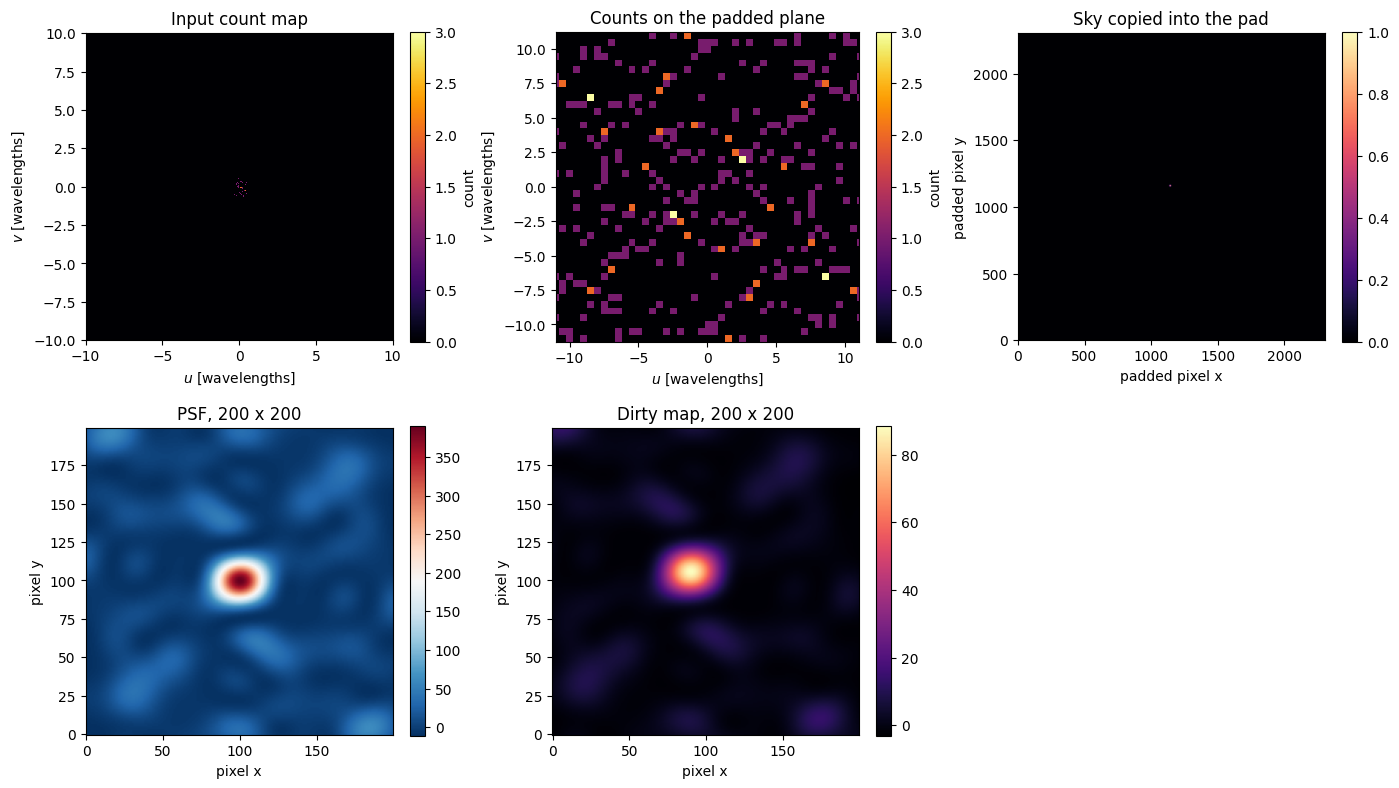

In [8]:
du, dv = 1.0, 1.25
nu, nv = 21, 17
u_edges = (np.arange(nu) - (nu - 1) / 2) * du
v_edges = (np.arange(nv) - (nv - 1) / 2) * dv
input_counts = np.zeros((nv - 1, nu - 1))
input_counts[nv // 2 - 1, :] = 4.0
input_counts[:, nu // 2 - 1] = 2.0
N_uv = (u_edges, v_edges, input_counts)

N_uv = N_uv_random

uv_map = inst.get_uvmap_halfwave(freq, N_uv=N_uv)
print(f'du = {inst.du:g}, dv = {inst.dv:g}')
print(f'n_pad = ({inst.n_pad_y}, {inst.n_pad_x}), uv_mode = {inst.uv_mode}')
print(f'input sum {input_counts.sum():.0f}, embedded sum {uv_map.sum():.0f}')

padded_sky = inst._pad_sky(sky)
psf_nuv = inst.get_psf(freq, N_uv=N_uv)
dirty_nuv = inst.get_dirty_map(sky, freq, N_uv=N_uv, noise=False)
print(f'PSF {psf_nuv.shape}, dirty map {dirty_nuv.shape}')

u_lim = np.abs(u_edges).max() + du
v_lim = np.abs(v_edges).max() + dv

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

im0 = axes[0, 0].imshow(
    N_uv[2],
    origin='lower',
    cmap='inferno',
    interpolation='none',
    extent=[u_edges[0], u_edges[-1], v_edges[0], v_edges[-1]],
)
axes[0, 0].set_title('Input count map')
axes[0, 0].set_xlabel(r'$u$ [wavelengths]')
axes[0, 0].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im0, ax=axes[0, 0], fraction=0.046, label='count')

im1 = axes[0, 1].imshow(
    uv_map,
    origin='lower',
    cmap='inferno',
    interpolation='none',
    extent=[inst.u_grid[0], inst.u_grid[-1], inst.v_grid[0], inst.v_grid[-1]],
)
axes[0, 1].set_xlim(-u_lim, u_lim)
axes[0, 1].set_ylim(-v_lim, v_lim)
axes[0, 1].set_aspect('equal')
axes[0, 1].set_title('Counts on the padded plane')
axes[0, 1].set_xlabel(r'$u$ [wavelengths]')
axes[0, 1].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im1, ax=axes[0, 1], fraction=0.046, label='count')

im2 = axes[0, 2].imshow(padded_sky, origin='lower', cmap='magma')
axes[0, 2].set_title('Sky copied into the pad')
axes[0, 2].set_xlabel('padded pixel x')
axes[0, 2].set_ylabel('padded pixel y')
fig.colorbar(im2, ax=axes[0, 2], fraction=0.046)

im3 = axes[1, 0].imshow(psf_nuv, origin='lower', cmap='RdBu_r')
axes[1, 0].set_title(f'PSF, {psf_nuv.shape[0]} x {psf_nuv.shape[1]}')
axes[1, 0].set_xlabel('pixel x')
axes[1, 0].set_ylabel('pixel y')
fig.colorbar(im3, ax=axes[1, 0], fraction=0.046)

im4 = axes[1, 1].imshow(dirty_nuv, origin='lower', cmap='magma')
axes[1, 1].set_title(f'Dirty map, {dirty_nuv.shape[0]} x {dirty_nuv.shape[1]}')
axes[1, 1].set_xlabel('pixel x')
axes[1, 1].set_ylabel('pixel y')
fig.colorbar(im4, ax=axes[1, 1], fraction=0.046)

axes[1, 2].axis('off')
fig.tight_layout()


## Check: UV complete gives you back the same sky

A count of 1 on every mode of the sky's own UV grid samples the whole Fourier transform. The dirty map of that coverage is the input sky.

570.1182778312198 5.758770483143621
599.5 1.0
UV plane 921 x 1152 (du=1, dv=1.25, 17.0 MB complex)
working grid (921, 1152), du=1, dv=1.25
counts min 1, max 1
max |dirty - sky| = 2.22e-16


/Users/hannahfronenberg/Documents/Code/LIMstat/src/limstat/fast_interferometer.py:410: UserWarning: 376609 counts fall outside the sky UV extent and were dropped.
  return self._apply_n_uv(*parsed)


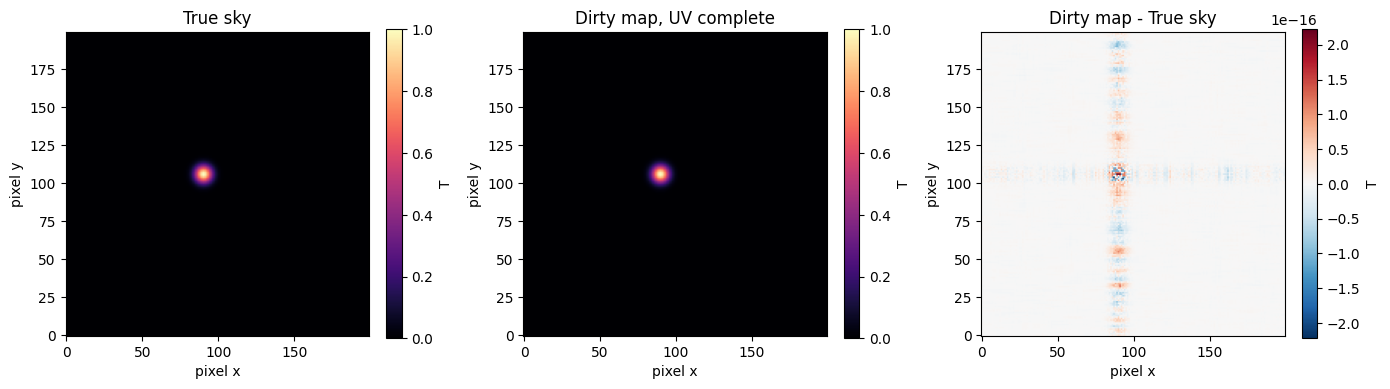

In [9]:
u_sky, v_sky, _, _, dl_sky, dm_sky = inst.sky_uv_coords()
# N_uv_complete = (u_sky, v_sky, np.ones_like(sky))
print(np.max(u_sky), np.median(np.diff(u_sky)))

#let's make another N_uv with a different du and dv but still all ones 
du, dv = 1.0, 1.25
nu, nv = 6*sky.shape[0], 6*sky.shape[1]
u_edges = (np.arange(nu) - (nu - 1) / 2) * du
v_edges = (np.arange(nv) - (nv - 1) / 2) * dv
N_uv_complete = (u_edges, v_edges, np.ones((nv - 1, nu - 1)))
print(np.max(u_edges), np.median(np.diff(u_edges))) 
# larger extent and finer sampling that the sky's own uv grid 

dirty_complete = inst.get_dirty_map(
    sky, freq, N_uv=N_uv_complete, noise=False,
)
residual = dirty_complete - sky
print(
    f'working grid {inst.count_map.shape}, du={inst.du:.6g}, dv={inst.dv:.6g}'
)
print(
    f'counts min {inst.count_map.min():.3g}, max {inst.count_map.max():.3g}'
)
print(f'max |dirty - sky| = {np.max(np.abs(residual)):.3g}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, image, title, cmap, label in (
    (axes[0], sky, 'True sky', 'magma', 'T'),
    (axes[1], dirty_complete, 'Dirty map, UV complete', 'magma', 'T'),
    (axes[2], residual, 'Dirty map - True sky', 'RdBu_r', 'T'),
):
    im = ax.imshow(image, origin='lower', cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046, label=label)
fig.tight_layout()

## Check: N-S baseline

Two antennas on a north-south line, imaged through the antenna path. Every baseline lies on the v axis, so a point source comes back as horizontal fringes: constant along x, varying along y.

2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
layout ns_only
rows constant: True
variation along x = 0, along y = 2.74e+03


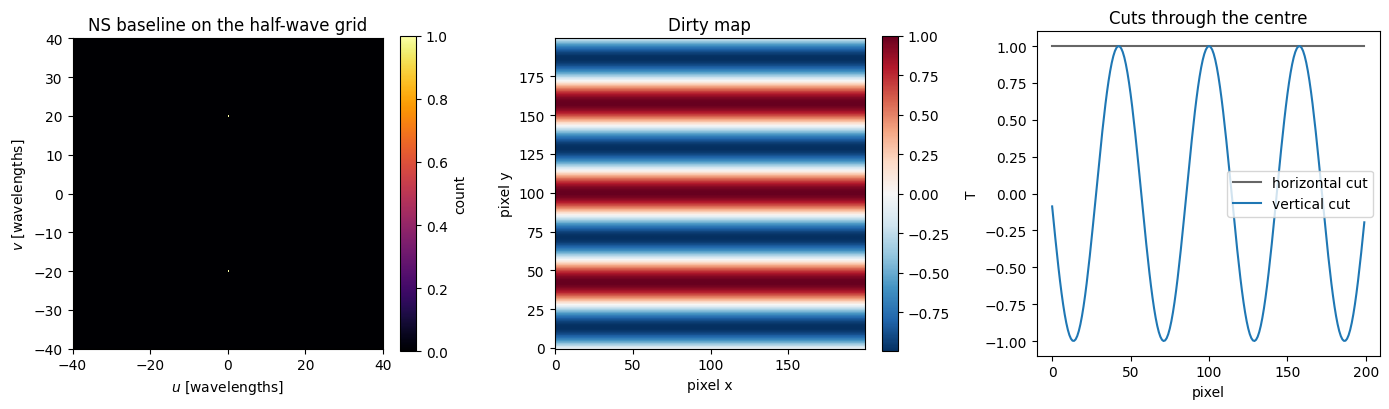

In [10]:
ns_ants = np.array([[0.0, -20.0], [0.0, 20.0]]) * units.m
point = np.zeros_like(sky)
point[npix // 2, npix // 2] = 1.0

dirty_ns = inst.get_dirty_map(point, freq, ant_locs=ns_ants, noise=False)

rows_constant = np.allclose(dirty_ns, dirty_ns[:, :1])
grad_x = np.abs(np.diff(dirty_ns, axis=1)).sum()
grad_y = np.abs(np.diff(dirty_ns, axis=0)).sum()
print(f'layout {inst.array_layout}')
print(f'rows constant: {rows_constant}')
print(f'variation along x = {grad_x:.3g}, along y = {grad_y:.3g}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
uv = inst.count_map
im0 = axes[0].imshow(
    uv,
    origin='lower',
    cmap='inferno',
    interpolation='none',
    extent=[inst.u_grid[0], inst.u_grid[-1], inst.v_grid[0], inst.v_grid[-1]],
)
axes[0].set_xlim(-40, 40)
axes[0].set_ylim(-40, 40)
axes[0].set_aspect('equal')
axes[0].set_title('NS baseline on the half-wave grid')
axes[0].set_xlabel(r'$u$ [wavelengths]')
axes[0].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im0, ax=axes[0], fraction=0.046, label='count')

im1 = axes[1].imshow(dirty_ns, origin='lower', cmap='RdBu_r')
axes[1].set_title('Dirty map')
axes[1].set_xlabel('pixel x')
axes[1].set_ylabel('pixel y')
fig.colorbar(im1, ax=axes[1], fraction=0.046)

cy, cx = npix // 2, npix // 2
axes[2].plot(dirty_ns[cy], color='0.4', label='horizontal cut')
axes[2].plot(dirty_ns[:, cx], color='C0', label='vertical cut')
axes[2].set_title('Cuts through the centre')
axes[2].set_xlabel('pixel')
axes[2].set_ylabel('T')
axes[2].legend()
fig.tight_layout()

## Check: EW baseline

Two antennas on an east-west line, imaged through the antenna path. Every baseline lies on the u axis, so a point source comes back as vertical fringes: constant along y, varying along x.

2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
layout ew_only
columns constant: True
variation along x = 2.74e+03, along y = 0


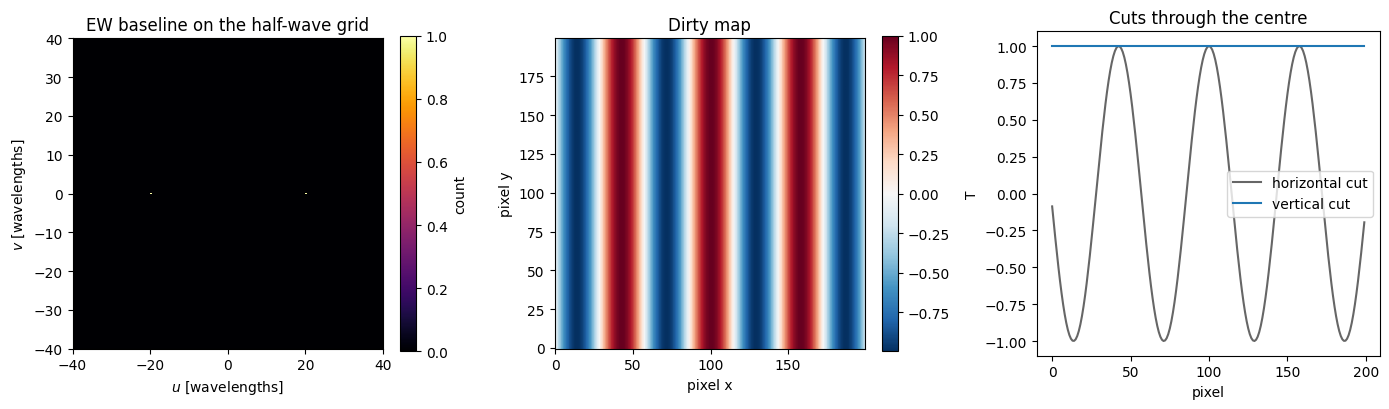

In [11]:
ew_ants = np.array([[-20.0, 0.0], [20.0, 0.0]]) * units.m
point = np.zeros_like(sky)
point[npix // 2, npix // 2] = 1.0

dirty_ew = inst.get_dirty_map(point, freq, ant_locs=ew_ants, noise=False)
columns_constant = np.allclose(dirty_ew, dirty_ew[:1, :])
grad_x = np.abs(np.diff(dirty_ew, axis=1)).sum()
grad_y = np.abs(np.diff(dirty_ew, axis=0)).sum()
print(f'layout {inst.array_layout}')
print(f'columns constant: {columns_constant}')
print(f'variation along x = {grad_x:.3g}, along y = {grad_y:.3g}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
uv = inst.count_map
im0 = axes[0].imshow(
    uv,
    origin='lower',
    cmap='inferno',
    interpolation='none',
    extent=[inst.u_grid[0], inst.u_grid[-1], inst.v_grid[0], inst.v_grid[-1]],
)
axes[0].set_xlim(-40, 40)
axes[0].set_ylim(-40, 40)
axes[0].set_aspect('equal')
axes[0].set_title('EW baseline on the half-wave grid')
axes[0].set_xlabel(r'$u$ [wavelengths]')
axes[0].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im0, ax=axes[0], fraction=0.046, label='count')

im1 = axes[1].imshow(dirty_ew, origin='lower', cmap='RdBu_r')
axes[1].set_title('Dirty map')
axes[1].set_xlabel('pixel x')
axes[1].set_ylabel('pixel y')
fig.colorbar(im1, ax=axes[1], fraction=0.046)

cy, cx = npix // 2, npix // 2
axes[2].plot(dirty_ew[cy], color='0.4', label='horizontal cut')
axes[2].plot(dirty_ew[:, cx], color='C0', label='vertical cut')
axes[2].set_title('Cuts through the centre')
axes[2].set_xlabel('pixel')
axes[2].set_ylabel('T')
axes[2].legend()
fig.tight_layout()


## Check: sparse point-source amplitude

A 1 K pixel observed with the east-west pair. The dirty-map peak is 1, and the map matches the PSF divided by its peak. A uniform weight of 1 cannot catch a wrong divisor, because the mean weight is then 1.


2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
dirty peak 1.000000
max |dirty - PSF/max| = 4.44e-16


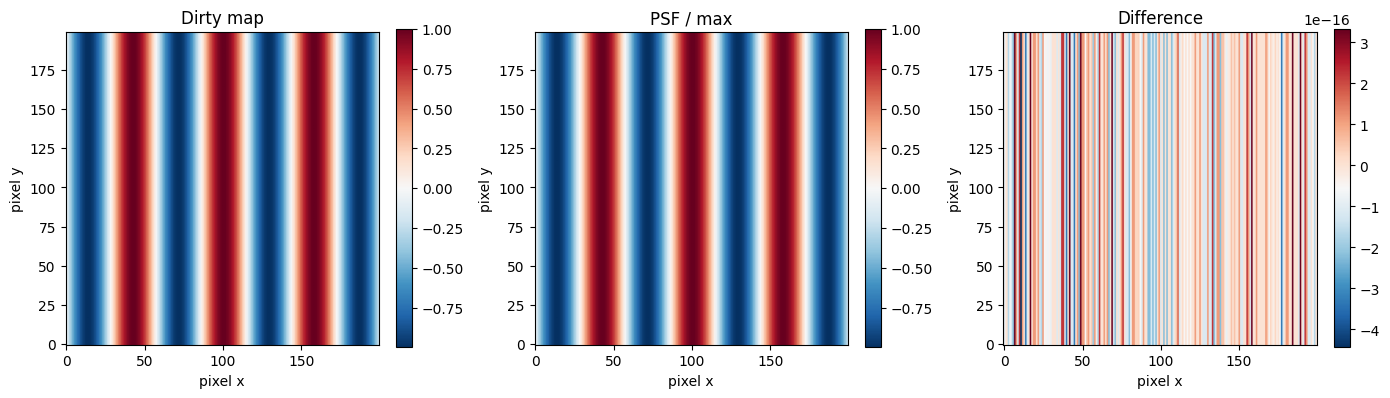

In [12]:
point = np.zeros_like(sky)
point[npix // 2, npix // 2] = 1.0

dirty_point = inst.get_dirty_map(point, freq, ant_locs=ew_ants, noise=False)
psf_ew = inst.get_psf(freq, ant_locs=ew_ants)
psf_norm = psf_ew / psf_ew.max()
print(f'dirty peak {dirty_point.max():.6f}')
print(f'max |dirty - PSF/max| = {np.max(np.abs(dirty_point - psf_norm)):.3g}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, image, title in (
    (axes[0], dirty_point, 'Dirty map'),
    (axes[1], psf_norm, 'PSF / max'),
    (axes[2], dirty_point - psf_norm, 'Difference'),
):
    im = ax.imshow(image, origin='lower', cmap='RdBu_r')
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()


## Check: shifted source

Move that pixel by 10 columns. The peak on the central row moves with it and stays at amplitude 1. The cropped image does not wrap, so the comparison is the overlapping columns.


2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
central-row peak at pixel 110, expected 110
amplitude at the source 1.000000
max |shifted - centred| on the overlap = 5.55e-16


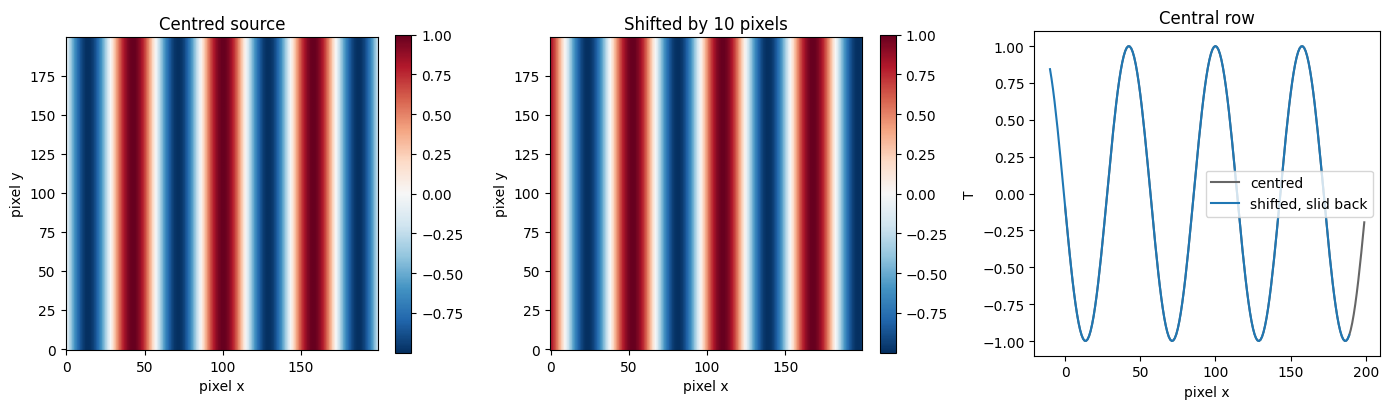

In [13]:
offset = 10
centre = np.zeros_like(sky)
centre[npix // 2, npix // 2] = 1.0
shifted = np.zeros_like(sky)
shifted[npix // 2, npix // 2 + offset] = 1.0

dirty_centre = inst.get_dirty_map(centre, freq, ant_locs=ew_ants, noise=False)
dirty_shift = inst.get_dirty_map(shifted, freq, ant_locs=ew_ants, noise=False)
row = npix // 2
cx_hat = int(np.argmax(dirty_shift[row]))
overlap = np.max(np.abs(dirty_shift[:, offset:] - dirty_centre[:, :-offset]))
print(f'central-row peak at pixel {cx_hat}, expected {npix // 2 + offset}')
print(f'amplitude at the source {dirty_shift[row, npix // 2 + offset]:.6f}')
print(f'max |shifted - centred| on the overlap = {overlap:.3g}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, image, title in (
    (axes[0], dirty_centre, 'Centred source'),
    (axes[1], dirty_shift, f'Shifted by {offset} pixels'),
):
    im = ax.imshow(image, origin='lower', cmap='RdBu_r')
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)

pixels = np.arange(npix)
axes[2].plot(pixels, dirty_centre[row], color='0.4', label='centred')
axes[2].plot(pixels - offset, dirty_shift[row], color='C0', label='shifted, slid back')
axes[2].set_title('Central row')
axes[2].set_xlabel('pixel x')
axes[2].set_ylabel('T')
axes[2].legend()
fig.tight_layout()


## Check: frequency scaling

The same east-west pair at 150 MHz and 300 MHz. The baseline's UV radius doubles, and the fringe period halves.


2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
2 total baseline vectors, 2 unique baseline vectors
UV plane 2304 x 2304 (du=0.5, dv=0.5, 84.9 MB complex)
|u| = 20 and 40 wavelengths, ratio 2
half period = 29 and 14 pixels, ratio 2.071


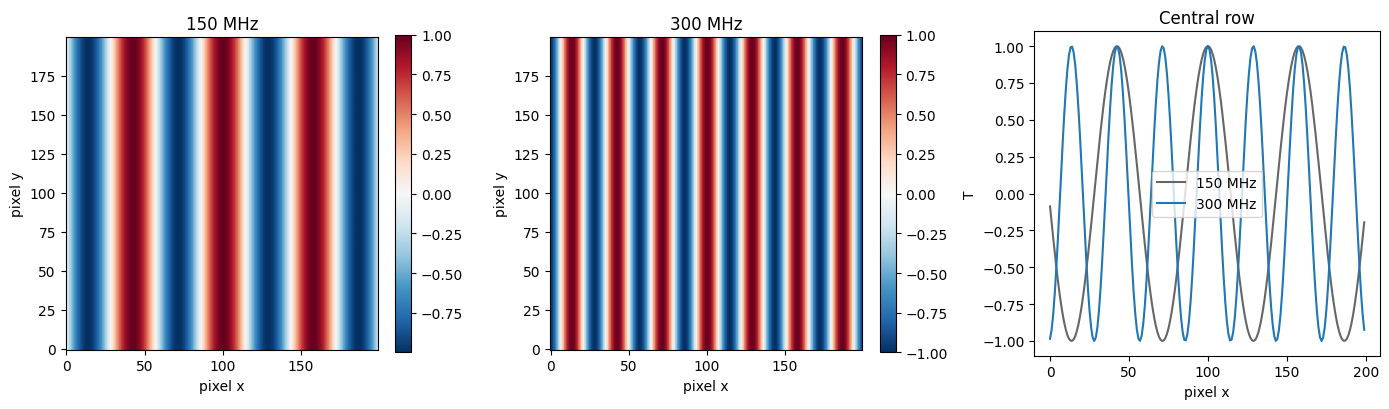

In [14]:
point = np.zeros_like(sky)
point[npix // 2, npix // 2] = 1.0
freq_hi = 2 * freq

dirty_lo = inst.get_dirty_map(point, freq, ant_locs=ew_ants, noise=False)
u_lo = np.max(np.abs(inst.u_coords))
dirty_hi = inst.get_dirty_map(point, freq_hi, ant_locs=ew_ants, noise=False)
u_hi = np.max(np.abs(inst.u_coords))

def half_period(row):
    """Pixels from the central peak to the first minimum."""
    slope = np.diff(row[len(row) // 2:])
    for i in range(1, len(slope)):
        if slope[i - 1] < 0 and slope[i] >= 0:
            return i
    raise RuntimeError('no fringe minimum on the central row')

half_lo = half_period(dirty_lo[npix // 2])
half_hi = half_period(dirty_hi[npix // 2])
print(f'|u| = {u_lo:.4g} and {u_hi:.4g} wavelengths, ratio {u_hi / u_lo:.4g}')
print(f'half period = {half_lo} and {half_hi} pixels, ratio {half_lo / half_hi:.4g}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, image, title in (
    (axes[0], dirty_lo, f'{freq.to(units.MHz).value:.0f} MHz'),
    (axes[1], dirty_hi, f'{freq_hi.to(units.MHz).value:.0f} MHz'),
):
    im = ax.imshow(image, origin='lower', cmap='RdBu_r')
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)

pixels = np.arange(npix)
axes[2].plot(pixels, dirty_lo[npix // 2], color='0.4', label='150 MHz')
axes[2].plot(pixels, dirty_hi[npix // 2], color='C0', label='300 MHz')
axes[2].set_title('Central row')
axes[2].set_xlabel('pixel x')
axes[2].set_ylabel('T')
axes[2].legend()
fig.tight_layout()


## Check: coarse and out-of-band N_uv

A count map coarser than the sky cell is resampled onto the sky grid. The beam is smooth and the dirty map of a broad source stays filled out to the corner. A cell past the sky Nyquist limit is dropped, so it does not alias into a fringe.


570.1182778312198 5.758770483143621
48.0 12.0
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
du_sky 5.759, supplied du 12, working du 5.759
beam peak 1.000000, shape (200, 200)
broad centre 138.5, corner 0.3524, exact zeros 0
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
sky Nyquist 575.9 wavelengths
out-of-band counts left 0, dirty max 0


/Users/hannahfronenberg/Documents/Code/LIMstat/src/limstat/fast_interferometer.py:810: UserWarning: 1 counts fall outside the sky UV extent and were dropped.
  uv_map = self.get_uvmap_halfwave(


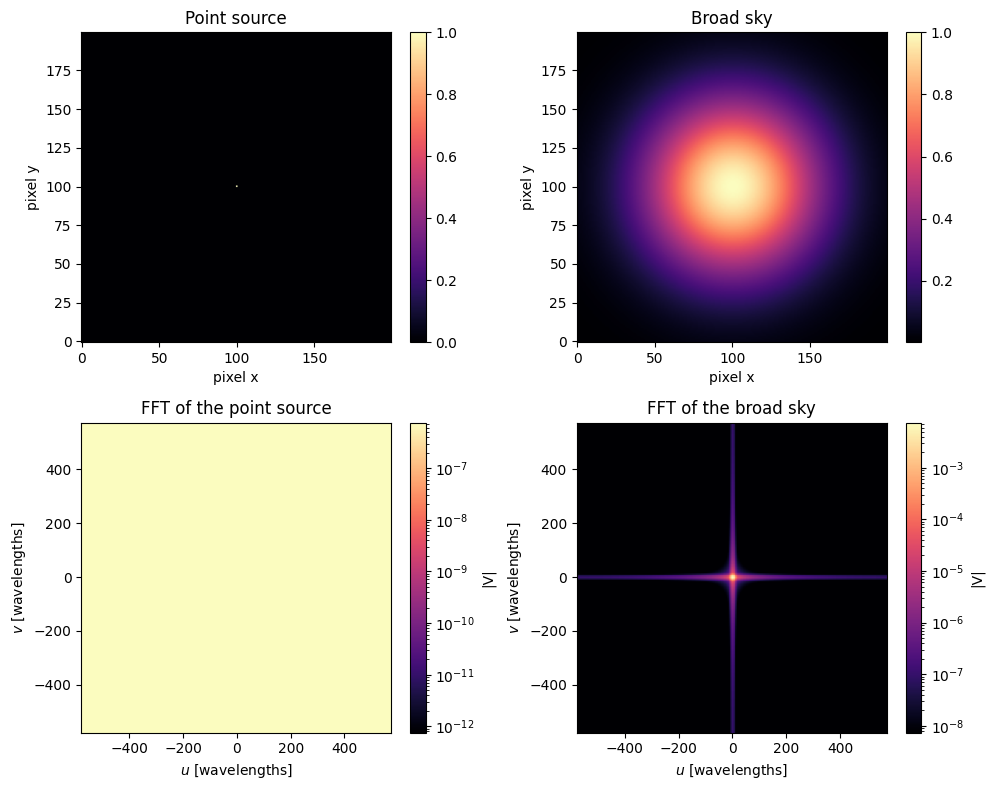

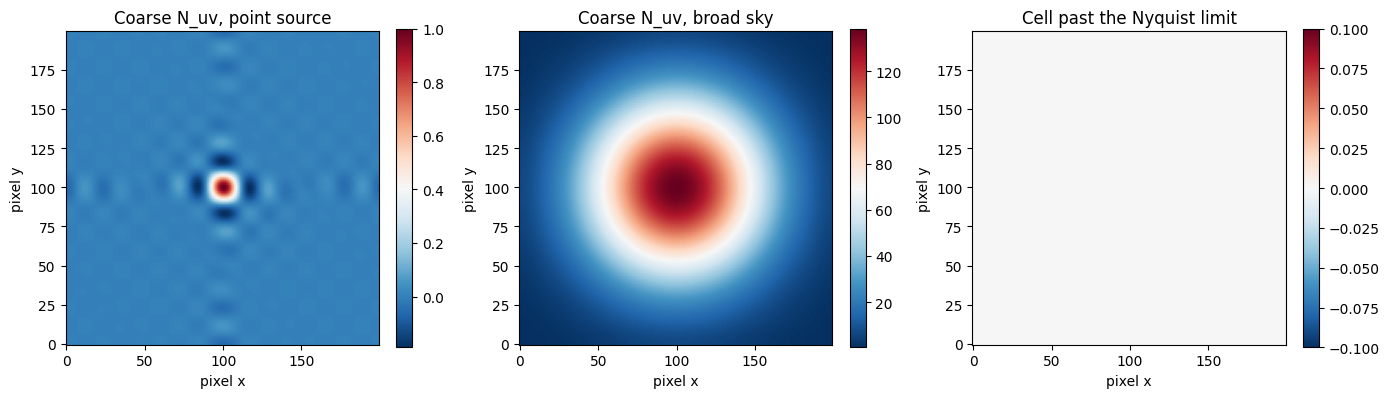

In [15]:
u_sky, _, _, _, dl_sky, _ = inst.sky_uv_coords()
du_sky = float(np.median(np.diff(u_sky)))
print(np.max(u_sky), np.median(np.diff(u_sky)))

# make a coarse gridded uvmap with smaller extent than the sky grid 
du_coarse = 12.0
nu = 9
edges = (np.arange(nu) - (nu - 1) / 2.0) * du_coarse
counts = np.ones((nu - 1, nu - 1))
print(np.max(edges), np.mean(np.diff(edges)))


point = np.zeros_like(sky)
point[npix // 2, npix // 2] = 1.0
yy, xx = np.mgrid[0:npix, 0:npix]
broad = np.exp(-((xx - npix // 2) ** 2 + (yy - npix // 2) ** 2) / (2 * 40.0 ** 2))

from matplotlib.colors import LogNorm

def sky_fft(image):
    return (
        np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image)))
        * (dl_sky ** 2)
    )

fft_point = np.abs(sky_fft(point))
fft_broad = np.abs(sky_fft(broad))
half_bin = 0.5 * du_sky
uv_extent = [
    u_sky[0] - half_bin, u_sky[-1] + half_bin,
    u_sky[0] - half_bin, u_sky[-1] + half_bin,
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, image, title in (
    (axes[0, 0], point, 'Point source'),
    (axes[0, 1], broad, 'Broad sky'),
):
    im = ax.imshow(image, origin='lower', cmap='magma')
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)

for ax, image, title in (
    (axes[1, 0], fft_point, 'FFT of the point source'),
    (axes[1, 1], fft_broad, 'FFT of the broad sky'),
):
    peak = np.max(image)
    im = ax.imshow(
        image, origin='lower', cmap='magma',
        norm=LogNorm(vmin=max(peak * 1e-6, 1e-30), vmax=max(peak, 1e-30)),
        extent=uv_extent,
    )
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.set_xlabel(r'$u$ [wavelengths]')
    ax.set_ylabel(r'$v$ [wavelengths]')
    fig.colorbar(im, ax=ax, fraction=0.046, label='|V|')
fig.tight_layout()

dirty_beam = inst.get_dirty_map(point, freq, N_uv=(edges, edges, counts), noise=False)
dirty_broad = inst.get_dirty_map(broad, freq, N_uv=(edges, edges, counts), noise=False)


print(f'du_sky {du_sky:.4g}, supplied du {du_coarse:g}, working du {inst.du:.4g}')
print(f'beam peak {dirty_beam.max():.6f}, shape {dirty_beam.shape}')
print(
    f'broad centre {dirty_broad[npix // 2, npix // 2]:.4g}, '
    f'corner {dirty_broad[0, 0]:.4g}, exact zeros {int(np.sum(dirty_broad == 0))}'
)

u_out = np.array([690.0, 710.0])
v_out = np.array([-du_coarse / 2, du_coarse / 2])
dirty_out = inst.get_dirty_map(
    point, freq, N_uv=(u_out, v_out, np.ones((1, 1))), noise=False,
)
print(f'sky Nyquist {0.5 / dl_sky:.4g} wavelengths')
print(
    f'out-of-band counts left {inst.count_map.sum():.3g}, '
    f'dirty max {np.max(np.abs(dirty_out)):.3g}'
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, image, title in (
    (axes[0], dirty_beam, 'Coarse N_uv, point source'),
    (axes[1], dirty_broad, 'Coarse N_uv, broad sky'),
    (axes[2], dirty_out, 'Cell past the Nyquist limit'),
):
    im = ax.imshow(image, origin='lower', cmap='RdBu_r')
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()


UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
original (8, 8) at du=12, refined (17, 17) at du=5.647, sky grid (200, 200) at du=5.759


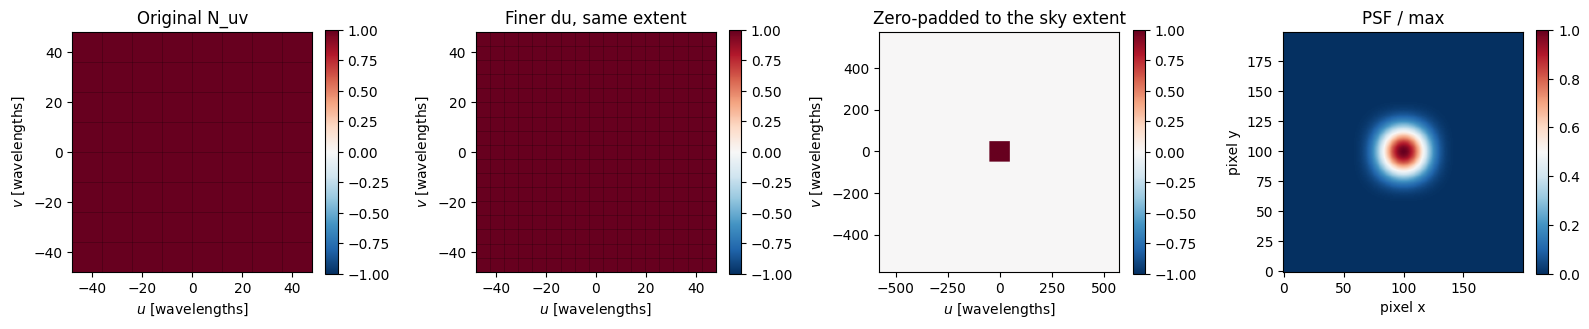

In [16]:
n_c = counts.shape[0]
width = n_c * du_coarse
n_fine = int(round(width / du_sky))
scale = du_coarse * du_coarse * n_c * n_c
beam = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(counts))) * scale
beam_pad = np.zeros((n_fine, n_fine), dtype=complex)
y0 = n_fine // 2 - beam.shape[0] // 2
beam_pad[y0:y0 + beam.shape[0], y0:y0 + beam.shape[1]] = beam
refined = np.real(
    np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(beam_pad))) / scale
)

full = np.zeros((npix, npix))
y0 = npix // 2 - n_fine // 2
full[y0:y0 + n_fine, y0:y0 + n_fine] = refined

u_cent = np.fft.fftshift(np.fft.fftfreq(npix, d=dl_sky))
du_cent = float(np.median(np.diff(u_cent)))
u_edges = np.empty(npix + 1)
u_edges[1:-1] = 0.5 * (u_cent[:-1] + u_cent[1:])
u_edges[0] = u_cent[0] - 0.5 * du_cent
u_edges[-1] = u_cent[-1] + 0.5 * du_cent
psf = inst.get_psf(freq, N_uv=(u_edges, u_edges, full), taper='blackmanharris', taper_kwargs={'scale': 1})
psf_norm = psf / psf.max()
print(
    f'original {counts.shape} at du={du_coarse:g}, '
    f'refined {refined.shape} at du={width / n_fine:.4g}, '
    f'sky grid {full.shape} at du={du_sky:.4g}'
)

half = width / 2
sky_extent = [u_edges[0], u_edges[-1], u_edges[0], u_edges[-1]]
refined_edges = np.linspace(-half, half, n_fine + 1)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.0))
panels = (
    (counts, [edges[0], edges[-1], edges[0], edges[-1]], edges, 'Original N_uv'),
    (refined, [-half, half, -half, half], refined_edges, 'Finer du, same extent'),
    (full, sky_extent, None, 'Zero-padded to the sky extent'),
)
for ax, (image, extent, cell_edges, title) in zip(axes[:3], panels):
    limit = np.max(np.abs(image))
    im = ax.imshow(
        image, origin='lower', cmap='RdBu_r',
        vmin=-limit, vmax=limit, extent=extent,
    )
    if cell_edges is not None:
        for coord in cell_edges:
            ax.axvline(coord, color='k', lw=0.4, alpha=0.35)
            ax.axhline(coord, color='k', lw=0.4, alpha=0.35)
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.set_xlabel(r'$u$ [wavelengths]')
    ax.set_ylabel(r'$v$ [wavelengths]')
    fig.colorbar(im, ax=ax, fraction=0.046)

im = axes[3].imshow(psf_norm, origin='lower', cmap='RdBu_r')
axes[3].set_title('PSF / max')
axes[3].set_xlabel('pixel x')
axes[3].set_ylabel('pixel y')
fig.colorbar(im, ax=axes[3], fraction=0.046)
fig.tight_layout()


NameError: name 'uv_zoom' is not defined

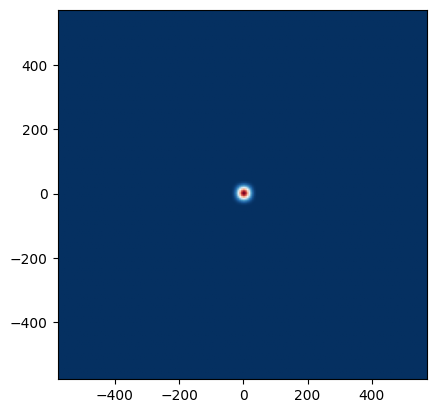

In [17]:
from scipy.signal.windows import blackmanharris

window = np.outer(blackmanharris(n_fine), blackmanharris(n_fine))
y0 = npix // 2 - n_fine // 2
full_bh = np.zeros_like(full)
full_bh[y0:y0 + n_fine, y0:y0 + n_fine] = refined * window

plt.imshow(full_bh, origin='lower', cmap='RdBu_r',extent=sky_extent)
plt.xlim(uv_zoom[0], uv_zoom[1])
plt.ylim(uv_zoom[2], uv_zoom[3])
plt.show()



psf_bh = inst.get_psf(freq, N_uv=(u_edges, u_edges, full_bh))
psf_bh_norm = psf_bh / psf_bh.max()

zoom = width
uv_zoom = [-zoom, zoom, -zoom, zoom]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, image, title in (
    (axes[0, 0], full, 'Zero-padded UV map'),
    (axes[1, 0], full_bh, 'Blackman-Harris on the aperture'),
):
    limit = np.max(np.abs(full))
    im = ax.imshow(
        image, origin='lower', cmap='RdBu_r',
        vmin=-limit, vmax=limit, extent=sky_extent,
    )
    ax.set_xlim(uv_zoom[0], uv_zoom[1])
    ax.set_ylim(uv_zoom[2], uv_zoom[3])
    ax.set_aspect('equal')
    ax.set_title(title)
    ax.set_xlabel(r'$u$ [wavelengths]')
    ax.set_ylabel(r'$v$ [wavelengths]')
    fig.colorbar(im, ax=ax, fraction=0.046)

for ax, image, title in (
    (axes[0, 1], psf_norm, 'PSF / max'),
    (axes[1, 1], psf_bh_norm, 'Tapered PSF / max'),
):
    im = ax.imshow(
        image, origin='lower', cmap='RdBu_r', vmin=-1, vmax=1,
    )
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()




## Check: natural-weight normalisation

The UV weight is the sample count in each cell. The dirty map is the inverse transform of `weight * V`, divided by `sum(weight) * du * dv * dl * dm`. The PSF is that same inverse transform of the weights, with no division.

On the sky's own UV grid the divisor has a closed form. A weight of 1 in every cell gives `npix**2 * du * dv * dl * dm = 1`, so the dirty map equals the sky. A weight of 4 makes the divisor 4 and multiplies the PSF peak by 4. A 1 K point source still peaks at 1, and its dirty map equals the PSF divided by its maximum.

UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
weight of 1: divisor 1 (analytic 1)
max |dirty sky - sky| = 5.55e-16
point-source peak 1
max |dirty point - psf/max| = 4.44e-16
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
weight of 4: divisor 4 (analytic 4)
max |dirty sky - sky| = 5.55e-16
PSF peak ratio 4 (analytic 4)
point-source peak 1


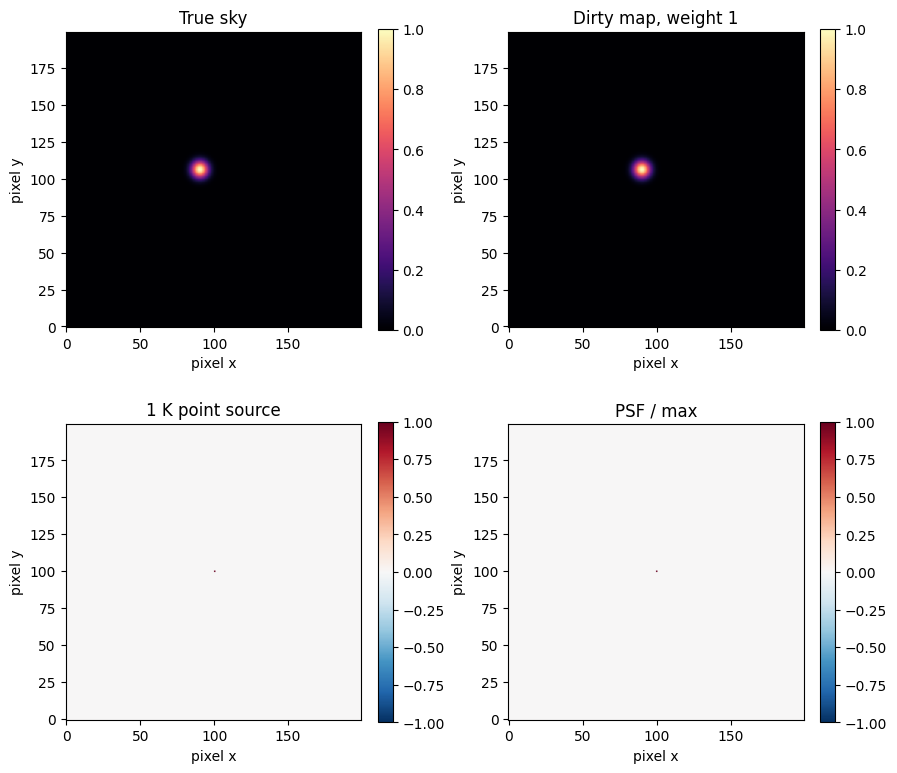

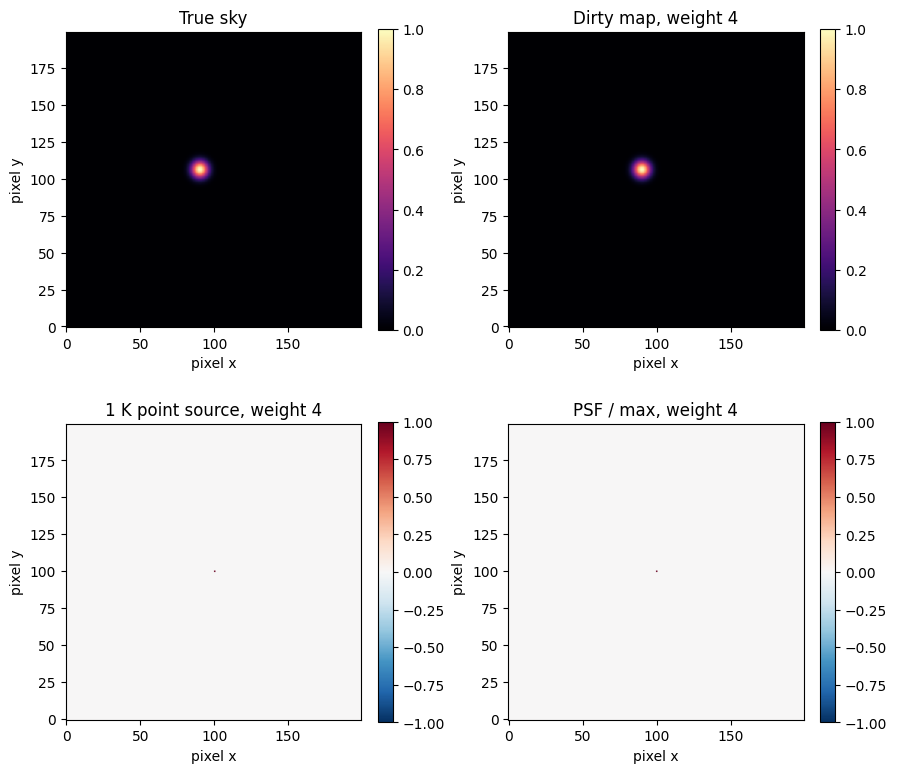

In [18]:
u_sky, v_sky, _, _, dl_sky, dm_sky = inst.sky_uv_coords()
du_sky = float(np.median(np.diff(u_sky)))
dv_sky = float(np.median(np.diff(v_sky)))
u_edges = np.concatenate([[u_sky[0] - du_sky / 2], 0.5 * (u_sky[:-1] + u_sky[1:]), [u_sky[-1] + du_sky / 2]])
v_edges = np.concatenate([[v_sky[0] - dv_sky / 2], 0.5 * (v_sky[:-1] + v_sky[1:]), [v_sky[-1] + dv_sky / 2]])

point = np.zeros((npix, npix))
point[npix // 2, npix // 2] = 1.0

N_uv_one = (u_edges, v_edges, np.ones((npix, npix)))
dirty_sky = inst.get_dirty_map(sky, freq, N_uv=N_uv_one, noise=False)
norm_one = float(np.sum(inst.count_map) * inst.du * inst.dv * dl_sky * dm_sky)
dirty_point = inst.get_dirty_map(point, freq, N_uv=N_uv_one, noise=False)
psf_one = inst.get_psf(freq, N_uv=N_uv_one)
psf_one_norm = psf_one / psf_one.max()
print(f'weight of 1: divisor {norm_one:.6g} (analytic 1)')
print(f'max |dirty sky - sky| = {np.max(np.abs(dirty_sky - sky)):.3g}')
print(f'point-source peak {dirty_point[npix // 2, npix // 2]:.6g}')
print(f'max |dirty point - psf/max| = {np.max(np.abs(dirty_point - psf_one_norm)):.3g}')

N_uv_four = (u_edges, v_edges, np.full((npix, npix), 4.0))
dirty_sky_four = inst.get_dirty_map(sky, freq, N_uv=N_uv_four, noise=False)
dirty_point_four = inst.get_dirty_map(point, freq, N_uv=N_uv_four, noise=False)
norm_four = float(np.sum(inst.count_map) * inst.du * inst.dv * dl_sky * dm_sky)
psf_four = inst.get_psf(freq, N_uv=N_uv_four)
psf_four_norm = psf_four / psf_four.max()
print(f'weight of 4: divisor {norm_four:.6g} (analytic 4)')
print(f'max |dirty sky - sky| = {np.max(np.abs(dirty_sky_four - sky)):.3g}')
print(f'PSF peak ratio {psf_four.max() / psf_one.max():.6g} (analytic 4)')
print(f'point-source peak {dirty_point_four[npix // 2, npix // 2]:.6g}')

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
panels = (
    (axes[0, 0], sky, 'True sky', 'magma', None),
    (axes[0, 1], dirty_sky, 'Dirty map, weight 1', 'magma', None),
    (axes[1, 0], dirty_point, '1 K point source', 'RdBu_r', (-1, 1)),
    (axes[1, 1], psf_one_norm, 'PSF / max', 'RdBu_r', (-1, 1)),
)
for ax, image, title, cmap, vlim in panels:
    kwargs = {'origin': 'lower', 'cmap': cmap}
    if vlim is not None:
        kwargs['vmin'], kwargs['vmax'] = vlim
    im = ax.imshow(image, **kwargs)
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
panels = (
    (axes[0, 0], sky, 'True sky', 'magma', None),
    (axes[0, 1], dirty_sky_four, 'Dirty map, weight 4', 'magma', None),
    (axes[1, 0], dirty_point_four, '1 K point source, weight 4', 'RdBu_r', (-1, 1)),
    (axes[1, 1], psf_four_norm, 'PSF / max, weight 4', 'RdBu_r', (-1, 1)),
)
for ax, image, title, cmap, vlim in panels:
    kwargs = {'origin': 'lower', 'cmap': cmap}
    if vlim is not None:
        kwargs['vmin'], kwargs['vmax'] = vlim
    im = ax.imshow(image, **kwargs)
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()

## Check: thermal noise

`compute_noise` is the standard deviation of one visibility, `T_sys * theta_x * theta_y / sqrt(bandwidth * t_obs)`. `get_noise_map` splits that between the real and imaginary parts, multiplies by the sample count, and divides by the same weight divisor as the dirty map.

On the all-ones sky grid that image rms is `sigma / (npix * dl * dm * sqrt(2))`. With `redundancy=True`, a count of 4 in every cell divides the visibility noise by `sqrt(4)` and multiplies the weight and the divisor by 4, so the image rms drops by 2.

UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.75877, 0.6 MB complex)
UV plane 200 x 200 (du=5.75877, dv=5.758

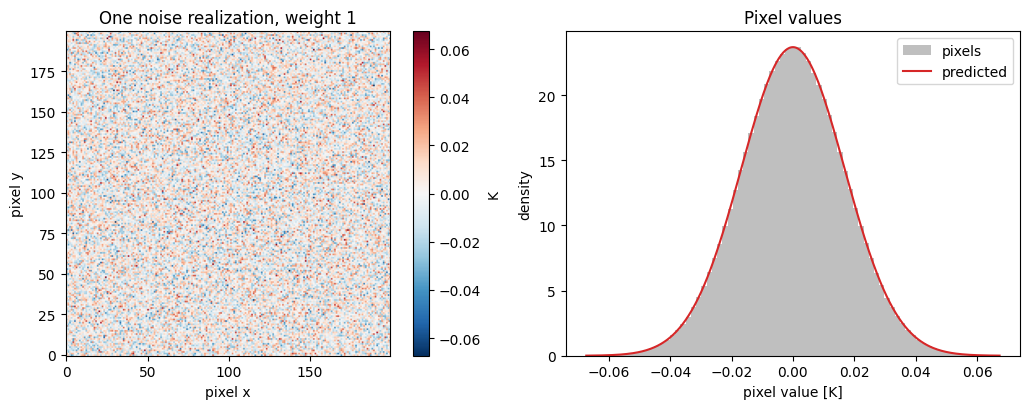

In [19]:
inst.T_sys = 200.0
inst.t_obs = (100 * units.hr).to(units.s).value
inst.bandwidth = (8 * units.MHz).to(units.Hz).value

sigma = inst.compute_noise()
rms_pred = sigma / (npix * dl_sky * dm_sky * np.sqrt(2))
n_real = 100

np.random.seed(0)
noise_one = np.stack([
    inst.get_noise_map(freq, redundancy=False, N_uv=N_uv_one)
    for _ in range(n_real)
])
rms_one = float(noise_one.std())

np.random.seed(1)
noise_four = np.stack([
    inst.get_noise_map(freq, redundancy=True, N_uv=N_uv_four)
    for _ in range(n_real)
])
rms_four = float(noise_four.std())
rms_pred_four = rms_pred / (np.sqrt(4))

print(f'visibility sigma {sigma:.6g} K')
print(f'image rms {rms_one:.6g} K, predicted {rms_pred:.6g} K, ratio {rms_one / rms_pred:.4f}')
print(f'count 4 rms {rms_four:.6g} K, predicted {rms_pred_four:.6g} K, ratio to the ones grid {rms_four / rms_one:.4f} (analytic 0.5)')

limit = 4 * rms_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
im = axes[0].imshow(
    noise_one[0], origin='lower', cmap='RdBu_r', vmin=-limit, vmax=limit,
)
axes[0].set_title('One noise realization, weight 1')
axes[0].set_xlabel('pixel x')
axes[0].set_ylabel('pixel y')
fig.colorbar(im, ax=axes[0], fraction=0.046, label='K')

bins = np.linspace(-limit, limit, 80)
axes[1].hist(
    noise_one.ravel(), bins=bins, density=True, color='0.75', label='pixels',
)
grid = np.linspace(-limit, limit, 400)
gauss = np.exp(-0.5 * (grid / rms_pred) ** 2) / (rms_pred * np.sqrt(2 * np.pi))
axes[1].plot(grid, gauss, color='C3', label='predicted')
axes[1].set_title('Pixel values')
axes[1].set_xlabel('pixel value [K]')
axes[1].set_ylabel('density')
axes[1].legend()
fig.tight_layout()